# Food-101 (20 classes): CNN trained from scratch

**Owner:** Trung Le

A 4-block convolutional network trained from random weights. Data split, training loop and metrics come from `common.py`, shared with the ResNet-50 notebook.

**On Google Colab:** Runtime → Change runtime type → GPU, then run this cell. Skip it when running locally.

In [1]:
!git clone https://github.com/Tinle0301/food101-cecs456.git
%cd food101-cecs456
!pip install -q -r requirements.txt

Cloning into 'food101-cecs456'...
remote: Enumerating objects: 25, done.
remote: Counting objects: 100% (25/25), done.
remote: Compressing objects: 100% (25/25), done.
remote: Total 25 (delta 13), reused 12 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (25/25), 11.04 KiB | 3.68 MiB/s, done.
Resolving deltas: 100% (13/13), done.
/content/food101-cecs456


In [2]:
import torch
import torch.nn as nn
from common import *

set_seed()
print('Device:', get_device())

Device: cuda


## 1. Data
Downloads Food-101 the first time (~5 GB) and creates `split.json`: 600 train / 150 validation / 250 test images per class.

In [12]:
# Set QUICK_TEST = True to check everything runs on a small subset first
QUICK_TEST = False
LIMIT = 300 if QUICK_TEST else 0

In [13]:
IMG_SIZE, BATCH_SIZE = 128, 64
loaders = get_loaders(IMG_SIZE, BATCH_SIZE, limit=LIMIT)
print({k: len(v.dataset) for k, v in loaders.items()})

{'train': 12000, 'val': 3000, 'test': 5000}


## 2. Model
Four blocks of (3×3 conv → BatchNorm → ReLU) ×2 → max pooling, with 32 → 64 → 128 → 256 channels, then global average pooling, dropout and a linear layer for the 20 classes.

In [14]:
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.MaxPool2d(2))


class ScratchCNN(nn.Module):
    def __init__(self, num_classes=20):
        super().__init__()
        self.features = nn.Sequential(conv_block(3, 32), conv_block(32, 64),
                                      conv_block(64, 128), conv_block(128, 256))
        self.classifier = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                        nn.Dropout(0.4), nn.Linear(256, num_classes))

    def forward(self, x):
        return self.classifier(self.features(x))


model = ScratchCNN(len(CLASSES))
print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')

Parameters: 1,178,356


## 3. Training
AdamW (lr 1e-3, weight decay 1e-4) with a cosine learning-rate schedule. The weights from the epoch with the best validation macro-F1 are kept.

In [15]:
EPOCHS = 2 if QUICK_TEST else 30
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
hist = train_model(model, loaders, optimizer, EPOCHS, 'scratch', scheduler)

Epoch  1/30 | train loss 2.654 acc 0.173 | val loss 2.530 acc 0.205 macro-F1 0.165
Epoch  2/30 | train loss 2.325 acc 0.272 | val loss 2.359 acc 0.266 macro-F1 0.221
Epoch  3/30 | train loss 2.083 acc 0.340 | val loss 2.353 acc 0.299 macro-F1 0.256
Epoch  4/30 | train loss 1.921 acc 0.396 | val loss 2.358 acc 0.284 macro-F1 0.236
Epoch  5/30 | train loss 1.790 acc 0.440 | val loss 1.971 acc 0.369 macro-F1 0.340
Epoch  6/30 | train loss 1.698 acc 0.463 | val loss 1.742 acc 0.444 macro-F1 0.428
Epoch  7/30 | train loss 1.615 acc 0.487 | val loss 1.623 acc 0.484 macro-F1 0.476
Epoch  8/30 | train loss 1.527 acc 0.523 | val loss 1.870 acc 0.446 macro-F1 0.407
Epoch  9/30 | train loss 1.459 acc 0.536 | val loss 1.799 acc 0.453 macro-F1 0.453
Epoch 10/30 | train loss 1.392 acc 0.560 | val loss 1.447 acc 0.542 macro-F1 0.526
Epoch 11/30 | train loss 1.328 acc 0.583 | val loss 1.377 acc 0.553 macro-F1 0.543
Epoch 12/30 | train loss 1.269 acc 0.602 | val loss 1.461 acc 0.561 macro-F1 0.554
Epoc

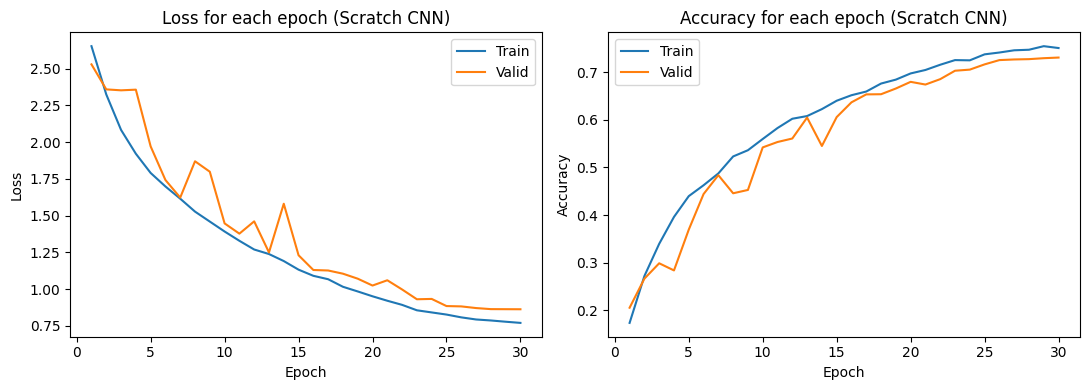

In [16]:
plot_curves(hist, 'Scratch CNN');

## 4. Test set results

In [17]:
res = evaluate(model, loaders, 'scratch')

Test set: loss 0.6755 | accuracy 0.7836 | precision 0.7818 | recall 0.7836 | f1 0.7819
Most confused (actual -> predicted): [['steak', 'filet_mignon', 63], ['filet_mignon', 'steak', 59], ['chocolate_cake', 'chocolate_mousse', 54], ['chocolate_mousse', 'chocolate_cake', 36], ['chocolate_mousse', 'ice_cream', 33]]


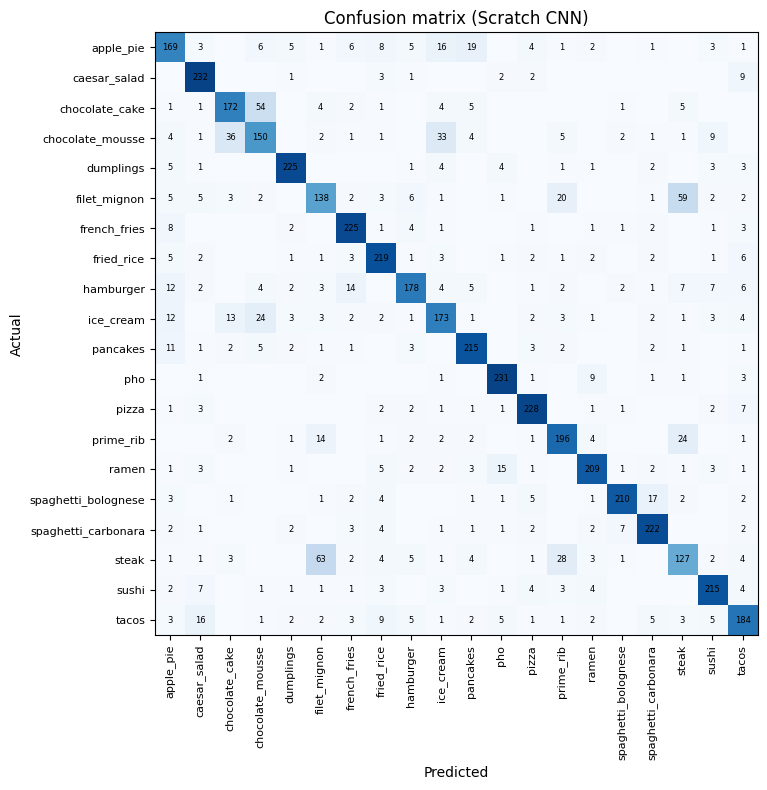

In [18]:
plot_confusion(res, 'Scratch CNN');

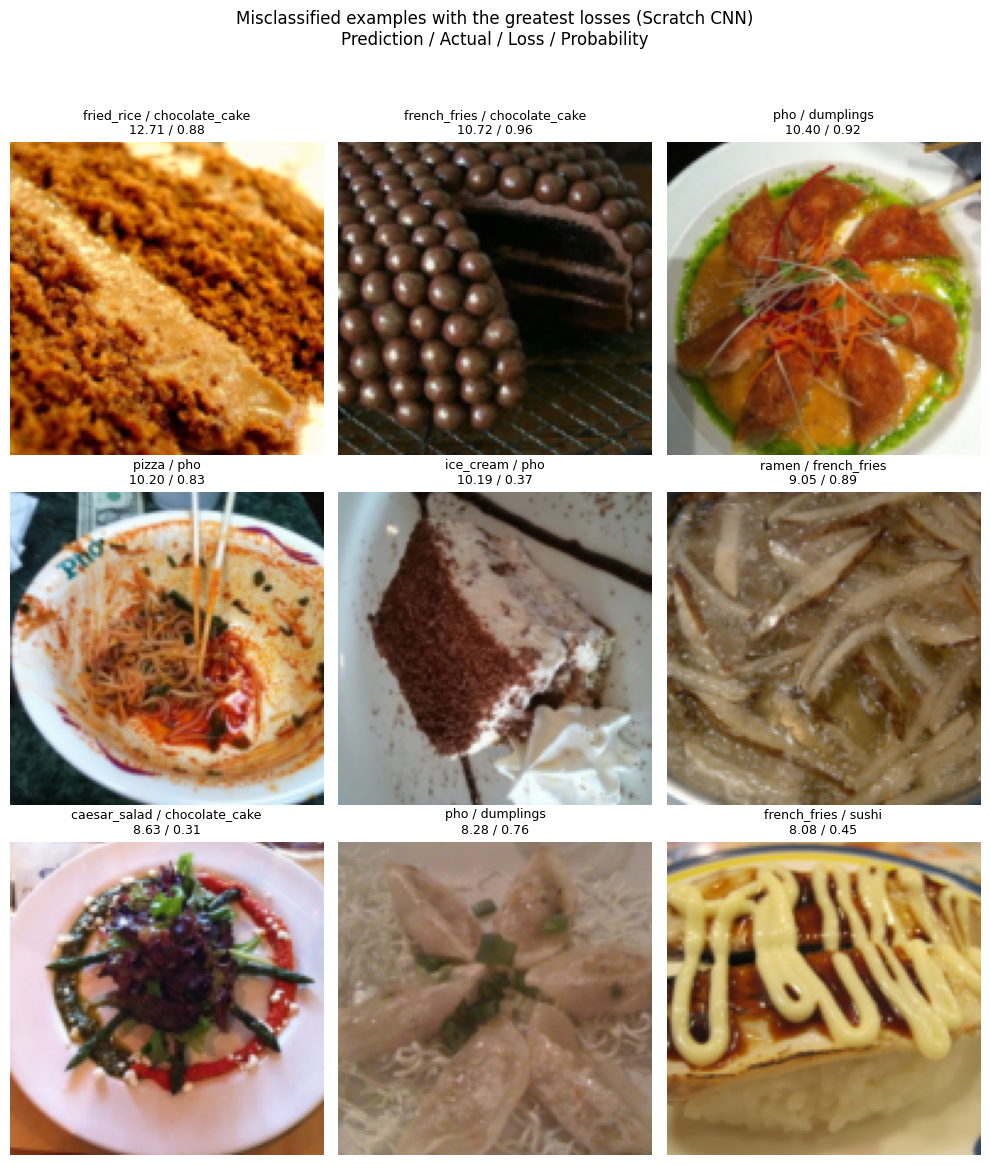

In [19]:
plot_top_losses(res, loaders, 'Scratch CNN');

## 5. Save results
Downloads a zip with the learning curves and test metrics (Colab deletes files when the session ends). Unzip it into your local repo folder, then commit and push.

In [20]:
download_results('scratch')

Saved results_scratch.zip: unzip it into the repo folder, then git add / commit / push.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

PosixPath('/content/food101-cecs456/results_scratch.zip')